In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk3-task2-spills.ipynb")

/opt/miniconda3/envs/eds220-env/lib/python3.11/site-packages/nbformat/validator.py:434: DuplicateCellId: Non-unique cell id '4d52d6d9-e745-43b4-9320-6f54aa03165d' detected. Corrected to '9004140b'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)
/opt/miniconda3/envs/eds220-env/lib/python3.11/site-packages/nbformat/validator.py:434: DuplicateCellId: Non-unique cell id 'cb27288e-e39c-424a-a6d9-91246bc5ccb8' detected. Corrected to '813ee033'.
  _validate(nbdict, ref, version, version_minor, relax_add_props)


# Task 2: Visualizing oil spills in NY State

## Instructions

- First, update the following cell to have a link to *your* Homework 3 GitHub repository:

**UPDATE THIS LINK**
https://github.com/eowen19/eds220-hwk3

- Review the [complete rubric for this task](https://docs.google.com/document/d/1Ce4EO3MEHW5uLks4x8BECWlkim2bcmxB4f8Qo4z26z8/edit?usp=sharing) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- Comment mindfully in a way that enriches your code. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.


## About the data
In this task you will use two datasets:

### First dataset: oil spills data

The first dataset contains information about [spilling incidents in the state of New York](https://data.ny.gov/Energy-Environment/Spill-Incidents/u44d-k5fk). Make sure you study the data portal and understand what each row represents before starting to code. 
You will find extra information and metadata for this dataset in the `NYSDEC_SpillIncidents_Overview.pdf` and `NYSDEC_SpillIncidents_DataDictionary.pdf` documents available at the portal.

### Second dataset: TIGER shapefile

The second dataset is the [2026 Counties (and equivalent) TIGER shapefile](https://www.census.gov/geographies/mapping-files/time-series/geo/tiger-line-file.2026.html) (file `tl_2026_us_county.zip`) from the Census Bureau. You can check the [metadata for all the TIGER shapefiles here](https://www.census.gov/programs-surveys/geography/technical-documentation/complete-technical-documentation/tiger-geo-line.html). 

### COMPLETE WORKFLOW
You will use the next code cell to complete the last exercise in the task. Leave it blank for now.

In [14]:
# FINAL CODE
# Import libraries
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

# Load the data
fp = os.path.join('data', 'tl_2026_us_county', 'tl_2026_us_county.shp')
counties = gpd.read_file(fp)
fp = os.path.join('data', 'Spill_Incidents_20261102.csv')
spills = gpd.read_file(fp)

# Clean the spills dataframe by removing capitalisation, spaces (replaced with underscores)
spills.columns = (spills.columns
                  .str.lower()
                  .str.replace(' ','_')
                  )

# Update `spill_date` to `datetime`
spills['spill_date'] = pd.to_datetime(spills['spill_date'])

# Isolate the spills dataframe to only petroleum spills between 01 January 2023 and 31 Decemeber 2023
petr_23 = spills[(spills['material_family'] == 'Petroleum') & (spills['spill_date'] >= '01/01/2023') & (spills['spill_date'] <= '12/31/2023')]

# Group the spills by county using `.groupby()`, then use `.rest_index()` to set the index to integers, then use `.rename()` to update the `spill_number` column to `n_spills`
spills_per_county = (petr_23.groupby('county').nunique()['spill_number']
                            .reset_index() 
                            .rename(columns = {"spill_number":"n_spills"}))

# Clean the counties dataframe by removing capitalisation
counties.columns = (counties.columns
                  .str.lower()
                  .str.replace(' ','_')
                  )

# Isolate the counties dataframe to only New York State counties
ny_counties = counties[counties['statefp'] == '36']

# Update St Lawrence County to read as St. Lawrence County
spills_per_county['county'] = spills_per_county['county'].replace('St Lawrence', 'St. Lawrence')

# Rename the `name` column within the ny_counties dataframe to `county`
ny_counties = ny_counties.rename(columns={"name":"county"})

# Use `pd.merge` to merge the ny_counties and spills_per_counties dataframes; ny_counties must be on the left to retain the geometries
ny_spills = pd.merge(ny_counties, spills_per_county, how='inner', on='county')

# Update Niagara and Onondaga counties to include the spills that occurred on the Tuscarora and Onondaga Indian Reservations
ny_spills.at[1, 'n_spills'] = 99
ny_spills.at[19, 'n_spills'] = 215

# Plot the total number of petroleum spills that occurred in New York State by County in 2023
fig, ax = plt.subplots()
ny_spills.plot(ax = ax, column = 'n_spills', legend=True)
ax.set_title('Number of Petroleum Spills in New York State in 2023')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.figtext(0.5, -0.01, 'Data sourced from the New York State Department of Environmental Conservation. Data acccessed: 02 November 2026', 
         ha='center', fontsize=8, style='italic')
plt.figtext(0.5, -0.05, 'Spills from the Onondaga and Tuscarora Indian Reservations are included in the Onondaga and Niagara County counts, respectively',
            ha = 'center', fontsize=8, style='italic')
plt.show()

<Figure size 640x480 with 2 Axes>

## 1. File management
a. Any data you download should go in the `data/` folder of your `eds220-hwk3` repository. For example, after downloading both datasets, your repository should look like this:

```
eds220-hwk3/
├── data/
│   ├── q5d_df.csv
│   ├── Spill_Incidents_20261027.csv
│   └── tl_2026_us_county/
│       ├── tl_2026_us_county.cpg
│       ├── tl_2026_us_county.dbf
│       ├── tl_2026_us_county.prj
│       ├── tl_2026_us_county.shp
│       └── ... (other files from the shapefile)
├── tests/
├── .gitignore
├── LICENSE
├── README.md
└── hwk3-task2-spills.ipynb
```

The date in the name of the spills file may be different, depending on when you download it. `data/q5d_df.csv` is already in the repository and is used by the autograder tests, so do not delete or move it.

**IMPORTANT: Do not commit your data!**

The datasets we'll be working with are large and will most likely jam your commit history if git does not ignore them.

b. Add the relative path of each dataset you downloaded to your `.gitignore` file. For example, to ignore the folder containing the shapefile, add `data/tl_2026_us_county/` to the `.gitignore`.

c. Commit and push your changes to the `.gitignore`.

d. Run `git status` and verify that none of your data is being tracked by git.

## 2. Datasets description
- Read the metadata for both datasets and write a brief description about each one. Indicate the data sources and date of access.

## 3. Import libraries

In [1]:
# Import libraries 
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import geopandas as gpd

## 4. Import data 
In the next cell:

- Import the NY spills data as a variable named `spills`. 
- Import the US counties data as a variable named `counties`.

If you are using file paths to access the data, these should be constructed using the `os` package.

In [2]:
# Load data
fp = os.path.join('data', 'tl_2026_us_county', 'tl_2026_us_county.shp')
counties = gpd.read_file(fp)

fp = os.path.join('data', 'Spill_Incidents_20261102.csv')
spills = gpd.read_file(fp)

<!-- BEGIN QUESTION -->

## 5. Prepare spills data

This section refers to the `spills` dataframe. 
Check the outputs carefully, they will give you information you will need to use in the next exercises.

### 5.A. Exploration

In the next cells:

a. Check the dataframe's head

b. Check the data types of the columns

c. Check the unique values in the `material_family` column

d. Check the unique values in the `county` column

e. Insert a markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells for preliminary data exploration.

The data frame has 21 columns that identify different types and locations of hazardous spills across the country.
All of datatypes are objects, with the exception of the geometry column, which has the dtype geometry. 
There are four unique values in the `material_family` column: 'Other', 'Petroleum', 'Hazardous Material', 'Oxygenates'. 
There are 87 unique values in the `county` column, which includes both counties and regions. 

In [4]:
#a. Check the dataframe's head
spills.head(2)

,Spill Number,Program Facility Name,Street 1,Street 2,Locality,County,ZIP Code,SWIS Code,DEC Region,Spill Date,...,Contributing Factor,Waterbody,Source,Close Date,Material Name,Material Family,Quantity,Units,Recovered,geometry
0,0107132,MH 864,RT 119/MILLWOOD RD,,ELMSFORD,Westchester,,6000,3,10/10/2001,...,Unknown,,Unknown,10/15/2001,unknown material,Other,10,Gallons,0,None
1,0405586,BOWRY BAY,WATER POLL CONTROL,,QUEENS,Queens,,4101,2,08/21/2004,...,Other,EAST RIVER,Unknown,09/17/2004,raw sewage,Other,0,,0,None


In [5]:
#b. Check the data types of the columns
spills.dtypes

Spill Number               object
Program Facility Name      object
Street 1                   object
Street 2                   object
Locality                   object
County                     object
ZIP Code                   object
SWIS Code                  object
DEC Region                 object
Spill Date                 object
Received Date              object
Contributing Factor        object
Waterbody                  object
Source                     object
Close Date                 object
Material Name              object
Material Family            object
Quantity                   object
Units                      object
Recovered                  object
geometry                 geometry
dtype: object

In [4]:
#c. Check the unique values in the `material_family` column
spills['Material Family'].unique()

array(['Other', 'Petroleum', 'Hazardous Material', 'Oxygenates'],
      dtype=object)

In [7]:
#d. Check the unique values in the `county` column
spills['County'].unique()

array(['Westchester', 'Queens', 'Bronx', 'Sullivan', 'Cortland',
       'New York', 'Ulster', 'Kings', 'Orange', 'Dutchess', 'Onondaga',
       'Saratoga', 'Cayuga', 'Oswego', 'Warren', 'Niagara', 'Rockland',
       'Nassau', 'Jefferson', 'Schenectady', 'Albany', 'Monroe',
       'Schuyler', 'St Lawrence', 'Richmond', 'Clinton', 'Lewis', 'Essex',
       'Chenango', 'Erie', 'Livingston', 'Oneida', 'Wayne', 'Suffolk',
       'Orleans', 'Ontario', 'Genesee', 'Otsego', 'Tompkins', 'Madison',
       'Chemung', 'Seneca', 'Broome', 'Hamilton', 'Washington', 'Steuben',
       'Rensselaer', 'Franklin', 'Columbia', 'Fulton', 'Herkimer',
       'Schoharie', 'Montgomery', 'Putnam', 'Delaware',
       'New Jersey - Region 2', 'Tioga', 'Chautauqua', 'Cattaraugus',
       'Wyoming', 'Yates', 'Greene', 'Pennsylvania - Region 9',
       'Allegany', 'New Jersey - Region 3 (N)',
       'Cattaraugus Indian Reservation', 'Connecticut - Region 3 (T)',
       'New Jersey - Region 3 (T)', 'Canada - Region 6',

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.B. Cleaning
a. Simplify column names as needed.

In [3]:
# Strip the column names to all lower case letters, replace spaces with underscores
spills.columns = (spills.columns
                  .str.lower()
                  .str.replace(' ','_')
                  )
print(spills.columns, '\n')

Index(['spill_number', 'program_facility_name', 'street_1', 'street_2',
       'locality', 'county', 'zip_code', 'swis_code', 'dec_region',
       'spill_date', 'received_date', 'contributing_factor', 'waterbody',
       'source', 'close_date', 'material_name', 'material_family', 'quantity',
       'units', 'recovered', 'geometry'],
      dtype='object') 



<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Update column data types as needed.

In [4]:
# Update the date columns to datetime dtypes (from object dtypes)
spills['received_date'] = pd.to_datetime(spills['received_date'])
spills['spill_date'] = pd.to_datetime(spills['spill_date'])

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 5.C. Data selection

a. Select data about petroleum spills that took place between January 1 and December 31, 2023 (including both dates). Store it in a variable named `petr_23`. The data selection should occur in a single line. You may add cells as needed.

In [6]:
# Isolate the spills dataframe to only petroleum spills between 01 January 2023 and 31 Decemeber 2023
petr_23 = spills[(spills['material_family'] == 'Petroleum') & (spills['spill_date'] >= '01/01/2023') & (spills['spill_date'] <= '12/31/2023')]
petr_23

,spill_number,program_facility_name,street_1,street_2,locality,county,zip_code,swis_code,dec_region,spill_date,...,contributing_factor,waterbody,source,close_date,material_name,material_family,quantity,units,recovered,geometry
70,2307439,#2 F/O IN GULLY (SMITH RESIDENCE),3666 MIDDLE ROAD,,BURDETT,Schuyler,14818,4926,8,2023-12-08,...,Traffic Accident,,Tank Truck,12/18/2024,diesel,Petroleum,300,Gallons,0,None
220,2301892,*** TEST SPILL ***,*** TEST SPILL ***,,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,...,Tank Test Failure,,Unknown,07/12/2023,diesel,Petroleum,0,,0,None
221,2301892,*** TEST SPILL ***,*** TEST SPILL ***,,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,...,Tank Test Failure,,Unknown,07/12/2023,#2 fuel oil,Petroleum,0,Gallons,0,None
222,2301892,*** TEST SPILL ***,*** TEST SPILL ***,,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,...,Tank Test Failure,,Unknown,07/12/2023,gasoline,Petroleum,0,,0,None
223,2301892,*** TEST SPILL ***,*** TEST SPILL ***,,*** TEST SPILL ***,Onondaga,00000,3415,7,2023-06-06,...,Tank Test Failure,,Unknown,07/12/2023,kerosene [#1 fuel oil] (on-site consumption),Petroleum,0,,0,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
574319,2307849,ZIMINSKI RESIDENCE,1892 BEECH ST,,WANTAGH,Nassau,11793,3020,1,2023-12-26,...,Equipment Failure,,Private Dwelling,12/26/2023,#2 fuel oil,Petroleum,0.5,Gallons,0,None
574331,2208304,ZIMMERMAN - UST,19 MOUNTAIN AVENUE,,LARCHMONT,Westchester,,6032,3,2023-01-10,...,Equipment Failure,,Private Dwelling,,#2 fuel oil,Petroleum,0,,0,None
574444,2307406,ZIZIC - UST,4 AUTUMN RIDGE RD,,POUND RIDGE,Westchester,,6046,3,2023-12-07,...,Equipment Failure,,Private Dwelling,12/19/2023,#2 fuel oil,Petroleum,0,,0,None
574624,2301301,ZULTOWSKY - UST,514 PELHAM MANOR RD,,PELHAM,Westchester,,6044,3,2023-05-16,...,Equipment Failure,,Private Dwelling,07/11/2023,#2 fuel oil,Petroleum,0,,0,None


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use `print()` and f-strings to print a message verifying that `petr_23` only has data for 2023 and from January through December.
HINT: if you converted the `spill_date` column to datetime, you can use `petr_23['spill_date'].dt.year.unique()`.

In [ ]:
# Use print() and f-strings to verify the data within petr_23
print(f"The dataframe is composed of{petr_23['material_family'].unique()} spills from{petr_23['spill_date'].dt.year.unique()} only")

The dataframe is composed of['Petroleum'] spills from[2023] only


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Write tests using `assert` to verify that `petr_23` only has data for petroleum spills.

In [ ]:
# Use assert to verify petr_23 only contains petroleum spills
assert set(petr_23['material_family']) == {'Petroleum'}

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Use `print()` and f-strings to print the number of rows in `petr_23` and the number of unique spills (use the `spill_number` column). Are these numbers the same? In the next markdown cell, explain why this might be the case. Use complete sentences. You may use additional cells to explore the data if needed.

In [ ]:
# Use print() and f-strings to print the number of rows and unique spills in petr_23
print(f"There are {(petr_23.shape[0])} rows in petr_23 and there are {(petr_23['spill_number'].nunique())} unique spills in petr_23.")

There are 8468 rows in petr_23 and there are 8228 unique spills in petr_23.


Some spills are likely entered multiplied times (i.e., repeated), either due to entry errors or occurring in multiple regions/jurisdictions. 

<!-- END QUESTION -->

### 5.D. Data aggregation

Create new dataframe named `spills_per_county` with the number of petroleum spills per county from January to December 2023.

As you found in exercise 5.C.d, a spill can appear in more than one row. Make sure you count each spill only once. HINT: `nunique()`.

The resulting `spills_per_county` dataframe must be as follows:

- Index: integer numbers starting from 0
- Two columns only.
- Column one: county names, column name = `county`
- Column two: number of petroleum spills per county in 2023, column name = `n_spills`

You may add cells if needed for your data wrangling.

In [7]:
# Group the spills by county using `.groupby()`, then use `.rest_index()` to set the index to integers, then use `.rename()` to update the `spill_number` column to `n_spills`
spills_per_county = (petr_23.groupby('county').nunique()['spill_number']
                            .reset_index() # set the index to integers instead of county
                            .rename(columns = {"spill_number":"n_spills"}))
spills_per_county

,county,n_spills
0,Albany,224
1,Allegany,32
2,Bronx,152
3,Broome,80
4,Cattaraugus,45
...,...,...
61,Washington,115
62,Wayne,41
63,Westchester,855
64,Wyoming,27


In [11]:
grader.check("q5d")

q5d results: All test cases passed!

<!-- BEGIN QUESTION -->

## 6. Prepare counties data

This section refers to the `counties` geo-dataframe. 
Check the outputs carefully, they will give you context about the next exercises.

### 6.A. Exploration

In the next cells:

a. Check the geo-dataframe's head

b. Check the data types of the columns

c. Check the geo-dataframe's CRS

d. Plot the geo-dataframe

e. Use the next markdown cell to explain what information you obtained from the preliminary exploration. Use complete sentences.

You can add any other cells of preliminary data exploration.

The geo-dataframe's head shows 19 columns breaking down the regional, state, and county identifiers, as well as geo IDs and the geometries that build up the shapefile. 

The dtypes are primarily objects, with the geometry column as a column and the FUNCSTAT, ALAND, AWATER are int64. 

The CRS of the geodataframe is EPSG:4269. 

The plotted geodataframe presents a completed map of the United States, including Alaska, Hawaii, and Puerto Rico. 

In [ ]:
# Use head() to view the counties dataframe
counties.head(2)

,STATEFP,COUNTYFP,COUNTYNS,GEOID,GEOIDFQ,NAME,NAMELSAD,LSAD,CLASSFP,MTFCC,CSAFP,CBSAFP,METDIVFP,FUNCSTAT,ALAND,AWATER,INTPTLAT,INTPTLON,geometry
0,12,009,00295749,12009,0500000US12009,Brevard,Brevard County,06,H1,G4020,None,37340,None,A,2628767922,1403935652,+28.2983112,-080.7003334,"POLYGON ((-80.98725 28.61300, -80.98674 28.613..."
1,06,055,00277292,06055,0500000US06055,Napa,Napa County,06,H1,G4020,488,34900,None,A,1947608455,104442639,+38.5073502,-122.3259960,"POLYGON ((-122.10363 38.51216, -122.10365 38.5..."


In [26]:
# Use dtypes to look at the data types of the columns
counties.dtypes

STATEFP       object
COUNTYFP      object
COUNTYNS      object
GEOID         object
GEOIDFQ       object
NAME          object
NAMELSAD      object
LSAD          object
CLASSFP       object
MTFCC         object
CSAFP         object
CBSAFP        object
METDIVFP      object
FUNCSTAT      object
ALAND          int64
AWATER         int64
INTPTLAT      object
INTPTLON      object
geometry    geometry
dtype: object

In [27]:
# Use .crs to identify the CRS of the geodataframe
counties.crs

<Geographic 2D CRS: EPSG:4269>
Name: NAD83
Axis Info [ellipsoidal]:
- Lat[north]: Geodetic latitude (degree)
- Lon[east]: Geodetic longitude (degree)
Area of Use:
- name: North America - onshore and offshore: Canada - Alberta; British Columbia; Manitoba; New Brunswick; Newfoundland and Labrador; Northwest Territories; Nova Scotia; Nunavut; Ontario; Prince Edward Island; Quebec; Saskatchewan; Yukon. Puerto Rico. United States (USA) - Alabama; Alaska; Arizona; Arkansas; California; Colorado; Connecticut; Delaware; Florida; Georgia; Hawaii; Idaho; Illinois; Indiana; Iowa; Kansas; Kentucky; Louisiana; Maine; Maryland; Massachusetts; Michigan; Minnesota; Mississippi; Missouri; Montana; Nebraska; Nevada; New Hampshire; New Jersey; New Mexico; New York; North Carolina; North Dakota; Ohio; Oklahoma; Oregon; Pennsylvania; Rhode Island; South Carolina; South Dakota; Tennessee; Texas; Utah; Vermont; Virginia; Washington; West Virginia; Wisconsin; Wyoming. US Virgin Islands. British Virgin Islands

<Axes: >

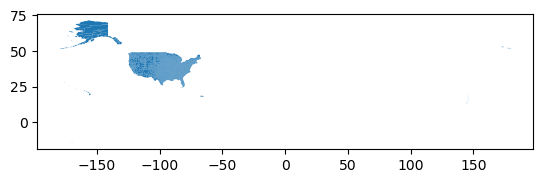

In [30]:
# Call .plot() to plot the geodataframe
counties.plot()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.B. Cleaning

Simplify column names as needed.

In [8]:
# Clean the counties dataframe by removing capitalisation
counties.columns = (counties.columns
                  .str.lower()
                  .str.replace(' ','_')
                  )
print(counties.columns, '\n')

Index(['statefp', 'countyfp', 'countyns', 'geoid', 'geoidfq', 'name',
       'namelsad', 'lsad', 'classfp', 'mtfcc', 'csafp', 'cbsafp', 'metdivfp',
       'funcstat', 'aland', 'awater', 'intptlat', 'intptlon', 'geometry'],
      dtype='object') 



<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

### 6.C. Data selection

Select all the counties for the state of New York in a new variable `ny_counties` and plot them (you may need to look at the metadata).

In [10]:
# Isolate the counties dataframe to only New York State counties
ny_counties = counties[counties['statefp'] == '36']
ny_counties

,statefp,countyfp,countyns,geoid,geoidfq,name,namelsad,lsad,classfp,mtfcc,csafp,cbsafp,metdivfp,funcstat,aland,awater,intptlat,intptlon,geometry
258,36,029,00974113,36029,0500000US36029,Erie,Erie County,06,H1,G4020,160,15380,None,A,2700743371,476876406,+42.7527590,-078.7781922,"POLYGON ((-78.77760 42.46188, -78.77756 42.461..."
259,36,063,00974130,36063,0500000US36063,Niagara,Niagara County,06,H1,G4020,160,15380,None,A,1352876142,1598772310,+43.2726719,-078.8129431,"POLYGON ((-78.49165 43.08396, -78.49179 43.084..."
338,36,045,00974121,36045,0500000US36045,Jefferson,Jefferson County,06,H1,G4020,None,48060,None,A,3283928401,1524534721,+43.9963890,-076.0529678,"POLYGON ((-75.90417 43.69796, -75.90437 43.697..."
352,36,101,00974148,36101,0500000US36101,Steuben,Steuben County,06,H1,G4020,236,18500,None,A,3601403364,35034920,+42.2667252,-077.3855253,"POLYGON ((-77.08327 42.00002, -77.09391 41.999..."
492,36,099,00974147,36099,0500000US36099,Seneca,Seneca County,06,H1,G4020,464,42900,None,A,838377561,172813845,+42.7822943,-076.8270880,"POLYGON ((-76.96393 43.01284, -76.96393 43.012..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2792,36,003,00974100,36003,0500000US36003,Allegany,Allegany County,06,H1,G4020,None,None,None,A,2666410162,12989705,+42.2478532,-078.0261531,"POLYGON ((-78.04342 42.51846, -78.04326 42.518..."
2829,36,017,00974107,36017,0500000US36017,Chenango,Chenango County,06,H1,G4020,None,None,None,A,2314006867,13433903,+42.4780238,-075.6022407,"POLYGON ((-75.40346 42.50870, -75.40331 42.508..."
3020,36,121,00974158,36121,0500000US36121,Wyoming,Wyoming County,06,H1,G4020,None,None,None,A,1535086368,9085227,+42.7013652,-078.2285762,"POLYGON ((-77.95538 42.71354, -77.95537 42.713..."
3110,36,033,00974115,36033,0500000US36033,Franklin,Franklin County,06,H1,G4020,None,None,None,A,4219867377,176612003,+44.5943758,-074.3106700,"POLYGON ((-74.38487 44.11157, -74.38667 44.111..."


<Axes: >

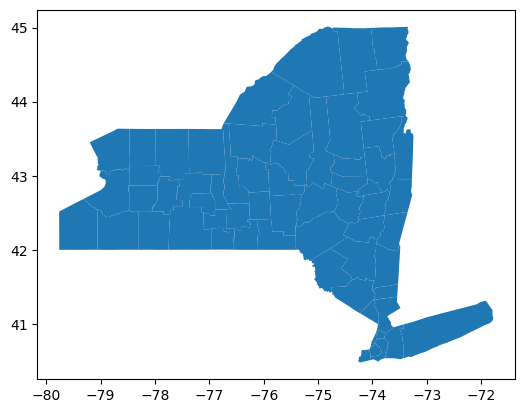

In [ ]:
# Use .plot() to plot the New York counties
ny_counties.plot()

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 7 Merging

The goal of this section is to create a single dataframe with the number of spills per county and the corresponding geometries for each county.

### 7.A. Explore data

In the next cells:

a. Print the names of counties in `ny_counties`, without repetition.


In [ ]:
# Print the names of counties in the ny_counties dataframe with no repetitions
print(ny_counties['name'].drop_duplicates())

258          Erie
259       Niagara
338     Jefferson
352       Steuben
492        Seneca
          ...    
2792     Allegany
2829     Chenango
3020      Wyoming
3110     Franklin
3120        Essex
Name: name, Length: 62, dtype: object


<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Print the names of counties in `spills_per_county`, without repetition. Examine the differences in the outputs.

In [ ]:
# Use print() the spills_per_county dataframe
print(spills_per_county)

         county  n_spills
0        Albany       224
1      Allegany        32
2         Bronx       152
3        Broome        80
4   Cattaraugus        45
..          ...       ...
61   Washington       115
62        Wayne        41
63  Westchester       855
64      Wyoming        27
65        Yates         7

[66 rows x 2 columns]


<!-- END QUESTION -->



c. Which are the county names that are in `spills_per_county`, but not in `ny_counties`? Your answer should be a list of strings
HINT: You can use the `numpy` function [`setdiff1d()`](https://numpy.org/doc/stable/reference/generated/numpy.setdiff1d.html), pay attention to the example in the documentation. Store your answer in the `diff_names` variable. 


In [11]:
# Use np.array() and np.setdiff1d() to list the counties that appear in the spills_per_county dataframe but not in the ny_counties dataframe
ny_counties_array = np.array([ny_counties['name'].unique()])
spills_per_county_array = np.array([spills_per_county['county']])
diff_names_spills = np.setdiff1d(spills_per_county_array, ny_counties_array)
diff_names_spills

array(['New Jersey - Region 2', 'Onondaga Indian Reservation',
       'Pennsylvania - Region 3', 'St Lawrence',
       'Tuscarora Indian Reservation'], dtype=object)

In [16]:
grader.check("7Ac")

7Ac results: All test cases passed!

d. Which are the county names that are in `ny_counties`, but not in `spills_per_county`? Your answer should be a list of a string/strings.


In [ ]:
# Use np.setdiff1d() to list the counties that appear in the ny_counties dataframe but not in the spills_per_county dataframe
diff_names_ny = np.setdiff1d(ny_counties_array, spills_per_county_array)
diff_names_ny

array(['St. Lawrence'], dtype=object)

In [18]:
grader.check("7Ad")

7Ad results: All test cases passed!

e. What is the number of spills in 'Tuscarora Indian Reservation' and in 'Onondaga Indian Reservation'?


In [ ]:
# e. Isolate the number of spills on the Tuscarora Indian Reservation and the Onondaga Indian Reservation
spill_tuscarora = spills_per_county[spills_per_county['county']=='Tuscarora Indian Reservation']
spill_tuscarora

spill_onondaga = spills_per_county[spills_per_county['county']=='Onondaga Indian Reservation']
spill_onondaga



,county,n_spills
35,Onondaga Indian Reservation,1


### 7.B. Data updates

In the next cell, update 'St Lawrence' to 'St. Lawrence' in the `spills_per_county` data frame. Verify the update was successful with an assert test. 


In [15]:
# Update the spelling of St. Lawrence County within the spills_per_county dataframe so that it matches the ny_counties dataframe
spills_per_county['county'] = spills_per_county['county'].replace('St Lawrence', 'St. Lawrence')
spills_per_county

,county,n_spills
0,Albany,224
1,Allegany,32
2,Bronx,152
3,Broome,80
4,Cattaraugus,45
...,...,...
61,Washington,115
62,Wayne,41
63,Westchester,855
64,Wyoming,27


### 7.C. Merge

In the following cells:

a. Use this cell to make any other updates needed for making an inner join of the `spills_per_county` and `ny_counties`. HINT: [`pd.merge`](https://pandas.pydata.org/pandas-docs/version/2.3/reference/api/pandas.merge.html)


In [ ]:
# Rename the 'name' column in ny_counties to 'county' to match the spills_per_county dataframe. 
ny_counties = ny_counties.rename(columns={"name":"county"})

b. Store the inner join of the `spills_per_county` and `ny_counties` dataframes in a new variable named `ny_spills`.


In [ ]:
# Use pd.merge() to merge the two dataframes into ny_spills
ny_spills = pd.merge(ny_counties, spills_per_county, how='inner', on='county')

<!-- BEGIN QUESTION -->

c. An inner join only keeps the rows whose `county` appears in both dataframes, and it does not warn you about the rows it drops. Which records from `spills_per_county` were dropped by the inner join, and how many spills did each one have? Add the cells you need to find the dropped records.

In [ ]:
# Use .isin() to check which counties are in spills_per_county but are not in the ny_spills dataframe
spills_per_county[~spills_per_county['county'].isin(ny_spills['county'])]

,county,n_spills
30,New Jersey - Region 2,7
35,Onondaga Indian Reservation,1
41,Pennsylvania - Region 3,1
58,Tuscarora Indian Reservation,2


New Jersey - Region 2: 7
Onondaga Indian Reservation: 1
Pennsylvania - Region 3: 1
St. Lawrence: 72
Tuscarora Indian Reservation: 2

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

d. Does dropping these records affect the map or the information we will report? Write your answer in the following markdown cell.

Dropping these records may provide a more accurate representation of activity occurring within New York State specifically if the spills within New Jersey - Region 2 and Pennsylvania - Region 3 were on the border but within the respective states, and not within New York. However, dropping the Onondaga Reservation and Tuscarora Reservation spills would alter the amount of spills that occurred within New York State. 

<!-- END QUESTION -->


From our previous exploration we know that Tuscarora Indian Reservation and Onondaga Indian Reservation will not be in the join. Tuscarora Indian Reservation is located within Niagara county and Onondaga Indian Reservation is located within Onondaga county. 

e. Since the reservations do not appear in the `ny_counties` dataframe, add the Tuscarora Indian Reservation spills to Niagara county and the Onondaga Indian Reservation spills to Onondaga county in `ny_spills`. We will add a note about this in our final map, and we will reflect on this choice in exercise 8.b. Add the cells you need to make this update **and** verify that the dataframe was updated.

In [17]:
# Update Niagara and Onondaga counties to include the spills that occurred on the Tuscarora and Onondaga Indian Reservations
ny_spills.at[1, 'n_spills'] = 99
ny_spills.loc[1]
ny_spills.at[19, 'n_spills'] = 215
ny_spills.loc[19]

statefp                                                    36
countyfp                                                  067
countyns                                             00974132
geoid                                                   36067
geoidfq                                        0500000US36067
county                                               Onondaga
namelsad                                      Onondaga County
lsad                                                       06
classfp                                                    H1
mtfcc                                                   G4020
csafp                                                     532
cbsafp                                                  45060
metdivfp                                                 None
funcstat                                                    A
aland                                              2016027811
awater                                               70512841
intptlat

## 8. Map
a. Create a choropleth map of the number of petroleum spills per county in the state of New York in 2023. 
Your map should be polished and have (at least) the following updates:
- a legend indicating the number of spills
- an updated color map
- a title 
- no axis
- an annotation with the data source (New York State Department of Environmental Conservation) and date of access



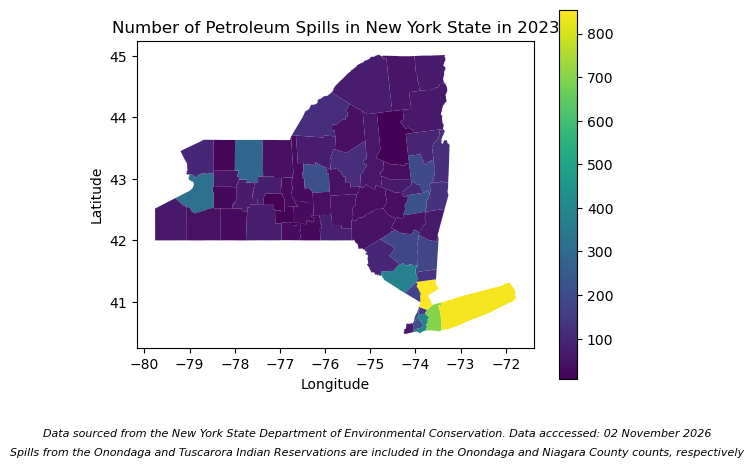

In [21]:
# Plot the total number of petroleum spills that occurred in New York State by County in 2023
fig, ax = plt.subplots()
ny_spills.plot(ax = ax, column = 'n_spills', legend=True)
ax.set_title('Number of Petroleum Spills in New York State in 2023')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
plt.figtext(0.5, -0.01, 'Data sourced from the New York State Department of Environmental Conservation. Data acccessed: 02 November 2026', 
         ha='center', fontsize=8, style='italic')
plt.figtext(0.5, -0.05, 'Spills from the Onondaga and Tuscarora Indian Reservations are included in the Onondaga and Niagara County counts, respectively',
            ha = 'center', fontsize=8, style='italic')
plt.show()

b. Write a description of how the map was created, including key takeaways. If you need to do additional data analysis to include relevant information from the data, you may include additional cells here.

In your description, also reflect on how we handled the spills reported in the Tuscarora and Onondaga Indian Reservations (exercise 7.C.e) in terms of data governance and the CARE Principles for Indigenous Data Governance from Task 1.

This map was created by cleaning, analysing, and merging two dataframes: ny_counties, which was sourced from a geospatial dataframe produced by the U.S. Census Bureau that contains the geometries for the counties of each state, and spills_per_county, which was sourced from dataframe produced by the New York State Department of Environmental Conservation and contained information on various hazardous spills that occurred across New York State. 

## Complete workflow

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the choropleth map of the number of petroleum spills per county in the state of New York in 2023. The only output of this cell should be the choropleth map  you produced in the previous exercise. Further guidance on what to include in this final workflow is in the assignment rubric.